![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Microwave Remote Sensing of Soil Moisture

Liquid water has a relative permittivity near 80 at microwave frequencies, dry soil minerals 3
to 5. Adding water to soil therefore changes how strongly the ground reflects and emits
microwaves, and that change is large enough to measure from orbit through clouds, day and night.
This notebook builds the physics chain behind every passive soil moisture product from the
permittivity of water, through dielectric mixing models of wet soil, Fresnel reflectivity and
roughness, to the tau-omega model of a vegetated surface. It then inverts that model (the single
channel algorithm), checks the inversion against the operational SMAP L3 Enhanced retrieval over
central Iowa, and measures how vegetation erodes the soil moisture signal.

## Overview

### Permittivity of water and of wet soil

The complex relative permittivity `eps = eps' - j eps''` describes how a material stores (`eps'`)
and absorbs (`eps''`) electromagnetic energy. Water molecules are dipoles that follow the field
until the frequency approaches their relaxation frequency (about 17 GHz at 20 C), so free water
follows the Debye model:

`eps_w = eps_inf + (eps_s - eps_inf) / (1 + j 2 pi f tau)`

with static permittivity `eps_s` (80 at 20 C), high-frequency limit `eps_inf` (4.9) and relaxation
time `tau` (9.3 ps at 20 C). Wet soil is a mixture of minerals, air, water bound to particle
surfaces and free water. Two mixing models are standard:

| Model | Inputs | Idea |
|---|---|---|
| Dobson et al. (1985), Peplinski et al. (1995) | soil moisture, sand, clay, bulk density, frequency, temperature | power-law mixing of the refractive indices of the components |
| Mironov et al. (2009) | soil moisture, clay, frequency | refractive mixing with separate bound and free water; the SMAP baseline |

### Reflectivity, emissivity and brightness temperature

For a smooth surface the Fresnel equations give the power reflectivity `r_p` at horizontal (`h`)
and vertical (`v`) polarization from `eps` and the incidence angle. By Kirchhoff's law the
emissivity is `e = 1 - r`, and a surface at temperature `T` emits the brightness temperature
`Tb = e T`. Roughness lowers the reflectivity, `r_rough = r exp(-h cos^N theta)` (Wang and
Choudhury 1981; SMAP uses `N = 2`).

### The tau-omega model

Vegetation absorbs and emits. In the zeroth-order radiative transfer (tau-omega) model (Mo et al.
1982) a canopy of nadir optical depth `tau` and single scattering albedo `omega` gives

`Tb = Ts e Gamma + Tc (1 - omega)(1 - Gamma)(1 + r Gamma)`, with `Gamma = exp(-tau / cos theta)`

The soil term is attenuated twice by the canopy (`Gamma`) and the canopy adds its own emission.
`tau` is roughly proportional to vegetation water content, `tau = b VWC` (Jackson and Schmugge
1991), with `b` about 0.1 at L-band.

### Frequency, depth and confounders

| Band | Frequency | Sensing depth | Vegetation | Missions |
|---|---|---|---|---|
| L | 1.4 GHz | about 5 cm | penetrates moderate canopies | SMAP, SMOS, NISAR (SAR) |
| C | 5.4 to 6.9 GHz | 1 to 2 cm | stronger attenuation | AMSR2, ASCAT, Sentinel-1 |
| X | 10.7 GHz | about 1 cm | saturates over crops | AMSR2 |

Other confounders: radio frequency interference (RFI) in the protected L-band, frozen soil (ice
has a permittivity of 3.2), open water in the footprint (very cold Tb), topography and snow.
Optical and thermal methods (the LST-NDVI triangle, OPTRAM) complement microwaves at finer
resolution and are developed in notebook 16.

## Microwave Physics with GeoLattice

| Function | Purpose |
|---|---|
| `sm.free_water_dielectric` | Debye permittivity of water, with optional ionic conductivity |
| `sm.dobson_dielectric`, `sm.mironov_dielectric`, `sm.topp_inverse` | permittivity of wet soil |
| `sm.penetration_depth` | power penetration depth (cm) |
| `sm.fresnel_reflectivity`, `sm.rough_reflectivity` | smooth and rough surface reflectivity |
| `sm.vwc_from_ndvi`, `sm.vod_from_vwc` | vegetation water content and optical depth |
| `sm.tau_omega`, `sm.invert_tau_omega` | forward model and single channel retrieval |
| `sm.tb_sensitivity` | Tb and dTb/dtheta for rising VOD |

### Learning objectives

1. Compute the permittivity of water and of wet soil, and compare the Dobson and Mironov models.
2. Explain why L-band senses deeper and through more vegetation than C- and X-band.
3. Build brightness temperature from reflectivity, roughness and the tau-omega model.
4. Retrieve soil moisture from brightness temperature and reproduce the SMAP retrieval.
5. Quantify how vegetation optical depth reduces sensitivity and how VOD errors become soil
   moisture errors.

### Data

| Dataset | Content |
|---|---|
| SoilGrids 2.0, SCAN Ames | clay and sand fractions of the top 5 cm |
| MODIS MOD13A1/MYD13A1 2024, central Iowa | 16-day NDVI at 500 m |
| SMAP L3 Enhanced (SPL3SMP_E v006) 2024, Iowa | brightness temperature, surface temperature, vegetation opacity and retrieved soil moisture at 9 km |

### Contents

- Setup
- Permittivity of water
- Permittivity of wet soil
- How deep the sensor sees
- Reflectivity, roughness and emission
- Vegetation water content and optical depth from NDVI
- Brightness temperature with the tau-omega model
- Retrieving soil moisture: the single channel algorithm
- Reproducing the SMAP retrieval
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

soil = sd.soilgrids_profile("SCAN Ames").loc["0-5cm"]  # SoilGrids top layer under SCAN Ames
SAND, CLAY = float(soil["sand"]), float(soil["clay"])  # texture fractions
theta = np.linspace(0.02, 0.50, 49)  # soil moisture axis (m3/m3)
print(f"SCAN Ames 0-5 cm: sand {SAND:.2f}, clay {CLAY:.2f}, bulk density {float(soil['bdod']):.2f} g/cm3")  # texture

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture
SCAN Ames 0-5 cm: sand 0.26, clay 0.30, bulk density 1.49 g/cm3


## Permittivity of water

The real part falls and the loss factor peaks as frequency approaches relaxation; warmer water
relaxes faster (the peak moves from 9 GHz at 0 C to 17 GHz at 20 C and 25 GHz at 35 C). At L-band
the real part stays near 80, so water contrasts strongly with dry soil whatever the temperature.

 0 C: eps' at 1.41 GHz  86.1, relaxation peak at 9.0 GHz
20 C: eps' at 1.41 GHz  79.6, relaxation peak at 17.3 GHz
35 C: eps' at 1.41 GHz  74.5, relaxation peak at 25.0 GHz


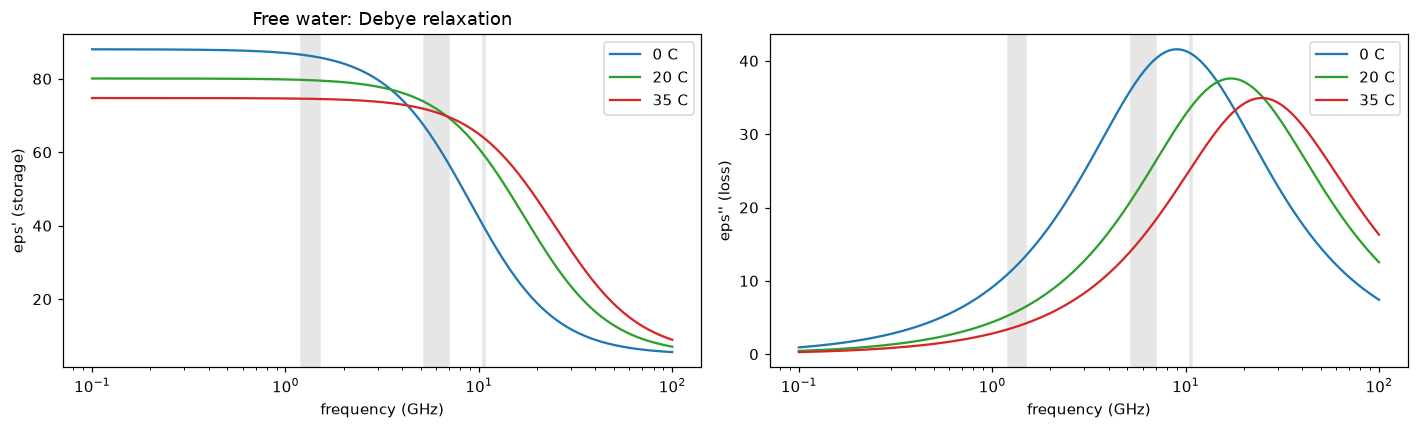

In [2]:
f = np.logspace(-1, 2, 300)  # 0.1 to 100 GHz
fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # real part and loss factor
for t, c in zip((0, 20, 35), ("tab:blue", "tab:green", "tab:red")):  # three temperatures
    e = sm.free_water_dielectric(f, t)  # Debye model
    ax[0].semilogx(f, e.real, color=c, label=f"{t} C"); ax[1].semilogx(f, -e.imag, color=c, label=f"{t} C")  # curves
    print(f"{t:2d} C: eps' at 1.41 GHz {sm.free_water_dielectric(1.41, t).real:5.1f}, relaxation peak at {f[np.argmax(-e.imag)]:.1f} GHz")  # numbers
for a, lab in zip(ax, ("eps' (storage)", "eps'' (loss)")):  # labels
    a.axvspan(1.2, 1.5, color="0.9"); a.axvspan(5.2, 7.0, color="0.9"); a.axvspan(10.5, 10.8, color="0.9")  # L, C, X bands
    a.set_xlabel("frequency (GHz)"); a.set_ylabel(lab); a.legend()  # axes
ax[0].set_title("Free water: Debye relaxation"); plt.tight_layout(); plt.show()  # draw

## Permittivity of wet soil

Both mixing models start near 2.5 for dry soil and rise steeply with moisture. The Topp equation,
an empirical TDR calibration, gives the apparent (real) permittivity for comparison.

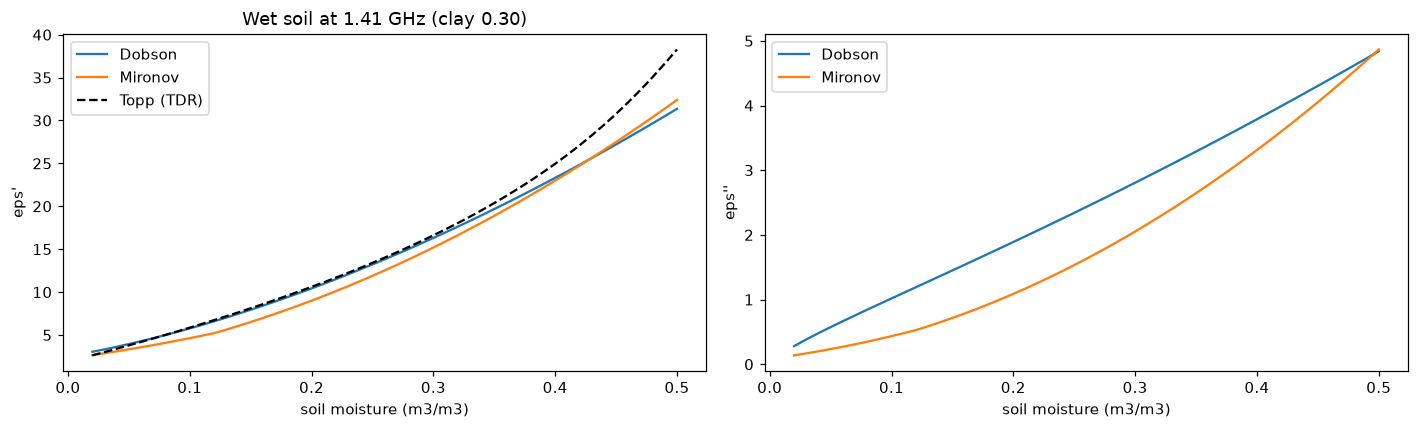

,Dobson,Mironov,Topp
0.05,3.9,3.3,3.8
0.15,7.9,6.5,8.1
0.25,13.2,11.9,13.4
0.35,19.7,18.9,20.4
0.45,27.2,27.5,30.8


In [3]:
dob = sm.dobson_dielectric(theta, SAND, CLAY, freq_ghz=1.41)  # Dobson (with Peplinski) at L-band
mir = sm.mironov_dielectric(theta, CLAY, freq_ghz=1.41)  # Mironov at L-band
top = sm.topp_inverse(theta)  # Topp apparent permittivity
fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # real and imaginary parts
ax[0].plot(theta, dob.real, label="Dobson"); ax[0].plot(theta, mir.real, label="Mironov"); ax[0].plot(theta, top, "k--", label="Topp (TDR)")  # real part
ax[1].plot(theta, -dob.imag, label="Dobson"); ax[1].plot(theta, -mir.imag, label="Mironov")  # loss factor
for a, lab in zip(ax, ("eps'", "eps''")):  # labels
    a.set_xlabel("soil moisture (m3/m3)"); a.set_ylabel(lab); a.legend()  # axes
ax[0].set_title(f"Wet soil at 1.41 GHz (clay {CLAY:.2f})"); plt.tight_layout(); plt.show()  # draw
cmp = pd.DataFrame({"Dobson": dob.real, "Mironov": mir.real, "Topp": top}, index=theta.round(2)).loc[[0.05, 0.15, 0.25, 0.35, 0.45]]  # table
display(cmp.round(1))  # real permittivity at five water contents

Over this loam the Dobson model gives 1 to 1.5 units more permittivity than Mironov up to 0.35
m3 m-3, and Topp lies close to Dobson. A difference of 1.3 in `eps'` near 0.25 m3 m-3 corresponds to
about 0.02 m3 m-3 of soil moisture, half of SMAP's accuracy target, so the choice of dielectric model
is itself a source of retrieval differences between products.

## How deep the sensor sees

The penetration depth `1 / (2 alpha)` is where the transmitted power falls to `1/e`.

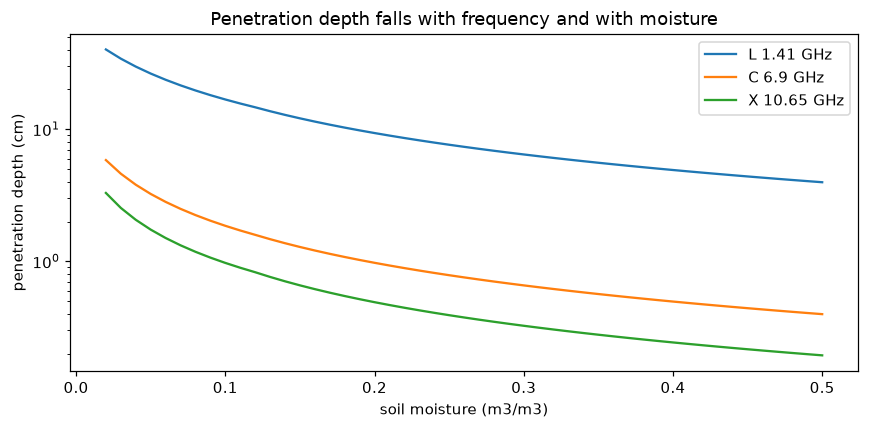

,L 1.41 GHz,C 6.9 GHz,X 10.65 GHz
0.05,26.4,3.2,1.7
0.20,9.4,1.0,0.5
0.35,5.6,0.6,0.3


In [4]:
pen = pd.DataFrame({band: sm.penetration_depth(sm.mironov_dielectric(theta, CLAY, freq_ghz=ghz), ghz)
                    for band, ghz in (("L 1.41 GHz", 1.41), ("C 6.9 GHz", 6.9), ("X 10.65 GHz", 10.65))}, index=theta)  # depth per band
ax = pen.plot(logy=True, figsize=(8, 4)); ax.set_xlabel("soil moisture (m3/m3)"); ax.set_ylabel("penetration depth (cm)")  # plot
ax.set_title("Penetration depth falls with frequency and with moisture"); plt.tight_layout(); plt.show()  # draw
display(pen.reindex([0.05, 0.20, 0.35], method="nearest").round(1))  # selected values

At L-band the signal comes from about 9 cm at 0.20 m3 m-3 and 6 cm at 0.35, and from much deeper in
very dry soil (26 cm at 0.05); at C-band from about 1 cm and at X-band from half a centimetre. Mironov's model is calibrated from 1.4 GHz upwards; at C- and X-band it is used here
for the trend, not for exact values. This is the physical reason the L-band missions SMAP and
SMOS were built for soil moisture.

## Reflectivity, roughness and emission

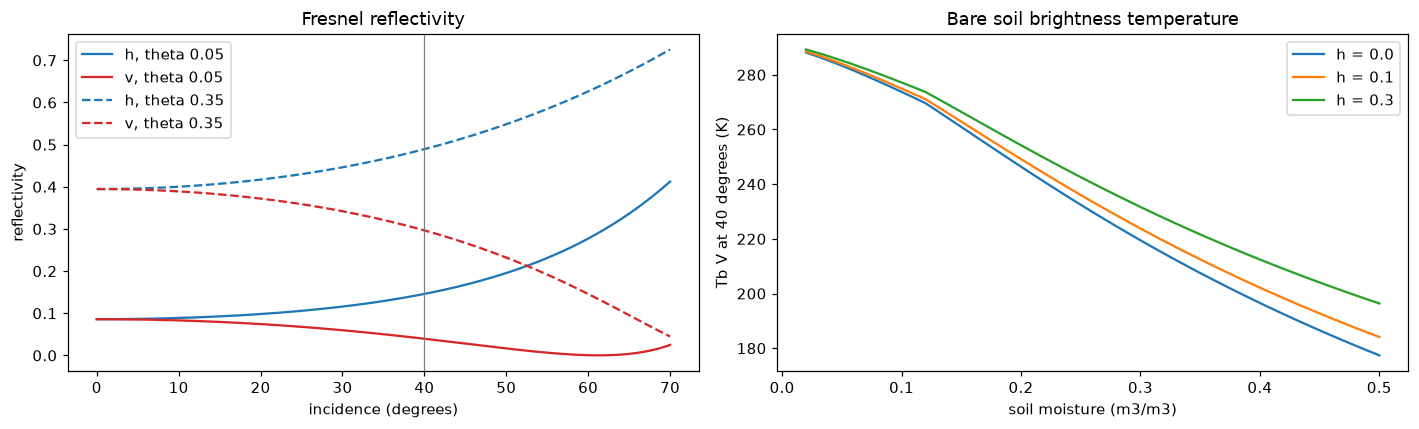

bare smooth soil: Tb V falls by 2.7 K per 0.01 m3/m3 between 0.1 and 0.4


In [5]:
inc = np.linspace(0, 70, 141)  # incidence angles (degrees)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # reflectivity and Tb
for th_, ls in ((0.05, "-"), (0.35, "--")):  # dry and wet soil
    e = sm.mironov_dielectric(th_, CLAY)  # permittivity
    for pol, c in (("h", "tab:blue"), ("v", "tab:red")):  # polarizations
        r = sm.fresnel_reflectivity(e, inc, pol=pol)  # smooth surface
        ax[0].plot(inc, r, ls=ls, color=c, label=f"{pol}, theta {th_}")  # reflectivity
ax[0].axvline(40, color="0.5", lw=0.8); ax[0].set_xlabel("incidence (degrees)"); ax[0].set_ylabel("reflectivity"); ax[0].legend()  # SMAP angle
tb_smooth = 295 * (1 - sm.fresnel_reflectivity(sm.mironov_dielectric(theta, CLAY), 40, pol="v"))  # smooth bare soil Tb
for h in (0.0, 0.1, 0.3):  # roughness parameter
    r = sm.rough_reflectivity(sm.fresnel_reflectivity(sm.mironov_dielectric(theta, CLAY), 40, pol="v"), 40, h=h)  # rough reflectivity
    ax[1].plot(theta, 295 * (1 - r), label=f"h = {h}")  # Tb of bare soil at 295 K
ax[1].set_xlabel("soil moisture (m3/m3)"); ax[1].set_ylabel("Tb V at 40 degrees (K)"); ax[1].legend()  # axes
ax[0].set_title("Fresnel reflectivity"); ax[1].set_title("Bare soil brightness temperature"); plt.tight_layout(); plt.show()  # draw
slope = np.polyfit(theta[(theta > 0.1) & (theta < 0.4)], tb_smooth[(theta > 0.1) & (theta < 0.4)], 1)[0]  # sensitivity
print(f"bare smooth soil: Tb V falls by {-slope / 100:.1f} K per 0.01 m3/m3 between 0.1 and 0.4")  # K per 0.01 m3/m3

V polarization reflects less than H at oblique angles (zero at the Brewster angle), and wet soil
reflects much more than dry soil. Over smooth bare soil a change of 0.01 m3 m-3 moves Tb V by 2.7 K,
about twice the radiometer noise of SMAP (about 1.3 K). Roughness raises Tb and flattens the
curve a little, which is why `h` must be known or calibrated.

## Vegetation water content and optical depth from NDVI

SMAP estimates vegetation water content from a 10-year NDVI climatology with the foliage formula
`1.9134 NDVI^2 - 0.3215 NDVI` plus a stem term that depends on land cover (Chan et al. 2013), and
converts it to optical depth with `tau = b VWC`. The 2024 MODIS NDVI of the central Iowa field
site shows the crop season.

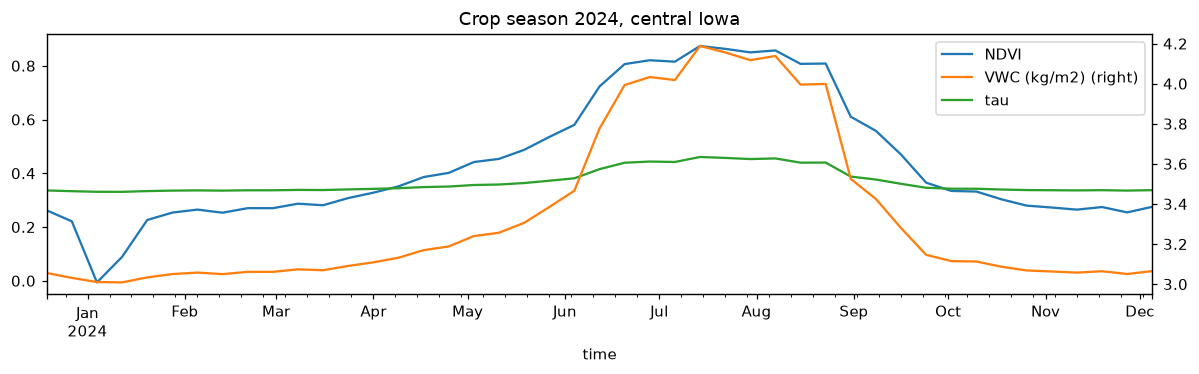

peak NDVI 0.87 on 14 Jul; peak VWC 4.2 kg/m2, tau 0.46


In [6]:
nd = sd.modis("ndvi")  # MODIS 16-day NDVI 2024, central Iowa (500 m)
ndvi = nd.ndvi.mean(("y", "x")).to_series().sort_index().resample("8D").mean().interpolate()  # area mean NDVI
vwc = sm.vwc_from_ndvi(ndvi, stem_factor=3.5, ndvi_max=float(ndvi.max()))  # foliage plus a crop stem term (kg/m2)
tau = sm.vod_from_vwc(vwc, b=0.11)  # nadir optical depth
veg = pd.DataFrame({"NDVI": ndvi, "VWC (kg/m2)": vwc, "tau": tau})  # one table
fig, ax = plt.subplots(figsize=(11, 3.5)); veg.plot(ax=ax, secondary_y=["VWC (kg/m2)"]); ax.set_title("Crop season 2024, central Iowa")  # plot
plt.tight_layout(); plt.show()  # draw
print(f"peak NDVI {ndvi.max():.2f} on {ndvi.idxmax():%d %b}; peak VWC {vwc.max():.1f} kg/m2, tau {tau.max():.2f}")  # peak values

NDVI peaks at 0.87 in mid-July, giving a vegetation water content of about 4.2 kg m-2 and an
optical depth of about 0.46: the range where L-band still sees the soil, but with much reduced
sensitivity. The stem factor (3.5 here, an illustrative value for crops) dominates at peak
season, which is one reason VWC is a main source of retrieval error over crops.

## Brightness temperature with the tau-omega model

This is the figure of course Notebook 2.1: brightness temperature against soil moisture for
rising optical depth, and the sensitivity `dTb/dtheta`.

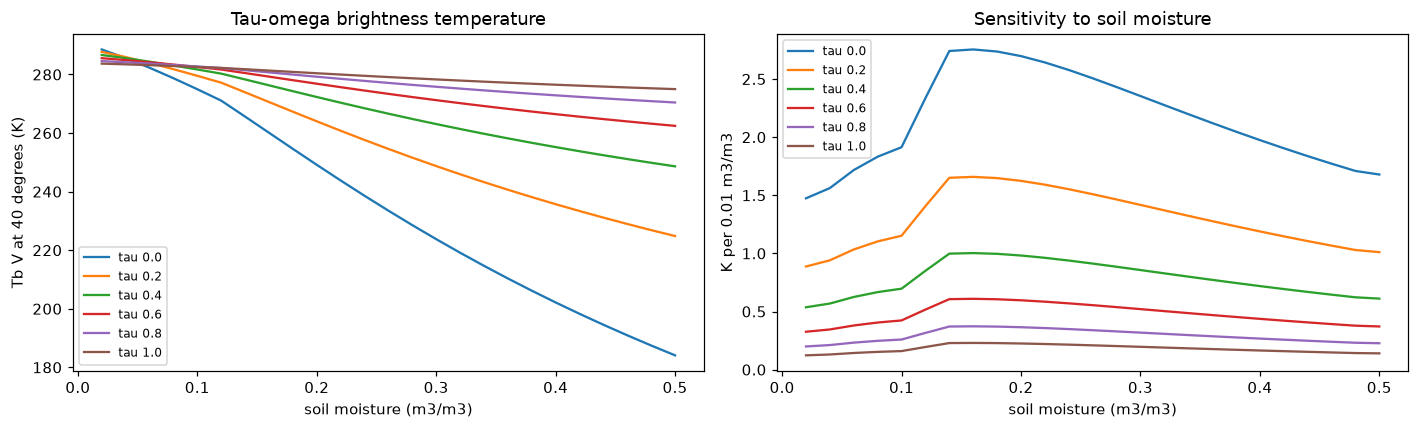

tau,0.0,0.2,0.4,0.6,0.8,1.0
K per 0.01 m3/m3,2.15,1.3,0.78,0.48,0.29,0.18


In [7]:
tab = sm.tb_sensitivity(tau_values=(0.0, 0.2, 0.4, 0.6, 0.8, 1.0), clay=CLAY, soil_temp_k=295.0, incidence_deg=40.0, pol="v")  # tidy table
fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # Tb and sensitivity
for t_, d in tab.groupby("tau"):  # one curve per tau
    ax[0].plot(d.theta, d.tb, label=f"tau {t_:.1f}"); ax[1].plot(d.theta, -d.dtb_dtheta / 100, label=f"tau {t_:.1f}")  # curves
ax[0].set_ylabel("Tb V at 40 degrees (K)"); ax[1].set_ylabel("K per 0.01 m3/m3")  # labels
for a in ax:  # shared x label
    a.set_xlabel("soil moisture (m3/m3)"); a.legend(fontsize=8)  # axes
ax[0].set_title("Tau-omega brightness temperature"); ax[1].set_title("Sensitivity to soil moisture"); plt.tight_layout(); plt.show()  # draw
sens = tab.groupby("tau").dtb_dtheta.mean().abs() / 100  # mean sensitivity per tau
display(sens.rename("K per 0.01 m3/m3").to_frame().T.round(2))  # table

Vegetation both warms Tb (its own emission) and shrinks the soil signal: the mean sensitivity falls
from 2.15 K per 0.01 m3 m-3 for bare soil to 0.78 at tau 0.4 and 0.18 at tau 1.0, twelve times less.
At tau 1.0 a 1 K radiometer error becomes a soil moisture error of about 0.05 m3 m-3. Dense canopies (forests, tau above about 0.8) are therefore flagged
by SMAP as retrievals of lower quality.

## Retrieving soil moisture: the single channel algorithm

The single channel algorithm (SCA-V, the SMAP baseline) inverts the tau-omega model for soil
moisture from V-polarized Tb, given surface temperature, `tau`, `omega` and `h`. `sm.invert_tau_omega`
solves each pixel by bisection. A wrong VOD propagates into the retrieval:

In [8]:
true_theta = np.array([0.10, 0.20, 0.30, 0.40])  # true soil moisture
rows = []  # retrieval errors
for tau_true in (0.1, 0.3, 0.6):  # three canopies
    tb = sm.tau_omega(295.0, sm.mironov_dielectric(true_theta, CLAY), 40.0, tau=tau_true, pol="v")  # simulated Tb
    for err in (-0.2, 0.0, 0.2):  # VOD error of -20 %, 0 and +20 %
        ret = sm.invert_tau_omega(tb, 295.0, 40.0, clay=CLAY, tau=tau_true * (1 + err), pol="v")  # retrieval
        rows.append({"tau": tau_true, "VOD error": f"{err:+.0%}", **{f"theta {t:.2f}": r - t for t, r in zip(true_theta, ret)}})  # errors
display(pd.DataFrame(rows).set_index(["tau", "VOD error"]).round(3))  # retrieval minus truth (m3/m3)

theta 0.10  theta 0.20  theta 0.30  theta 0.40
tau VOD error                                                
0.1 -20%           -0.003      -0.007      -0.013      -0.021
    +0%            -0.000       0.000       0.000      -0.000
    +20%            0.003       0.007       0.014       0.023
0.3 -20%           -0.007      -0.018      -0.035      -0.056
    +0%            -0.000       0.000       0.000      -0.000
    +20%            0.007       0.021       0.043       0.071
0.6 -20%           -0.007      -0.029      -0.059      -0.094
    +0%            -0.000       0.000       0.000      -0.000
    +20%            0.005       0.037       0.085       0.151

With the right VOD the inversion returns the truth exactly. A VOD 20 % too high makes the
retrieval too wet (the model attributes too much of the warm Tb to vegetation), and the error grows
with the canopy and with soil moisture: at tau 0.3 it is +0.02 m3 m-3 at 0.20 and +0.04 at 0.30; at
tau 0.6 it reaches +0.085 at 0.30. Over mature crops VOD is the dominant error source.

## Reproducing the SMAP retrieval

SMAP L3 Enhanced carries the inputs of its own retrieval: the V-polarized Tb corrected for water
bodies, the effective surface temperature, the vegetation opacity and the roughness coefficient.
Feeding them into `sm.invert_tau_omega` with SoilGrids clay should reproduce the official soil
moisture closely if the physics is the same.

4,518 retrievals: R 0.958, mean difference -0.002, std 0.023 m3/m3, 90 % within 0.036


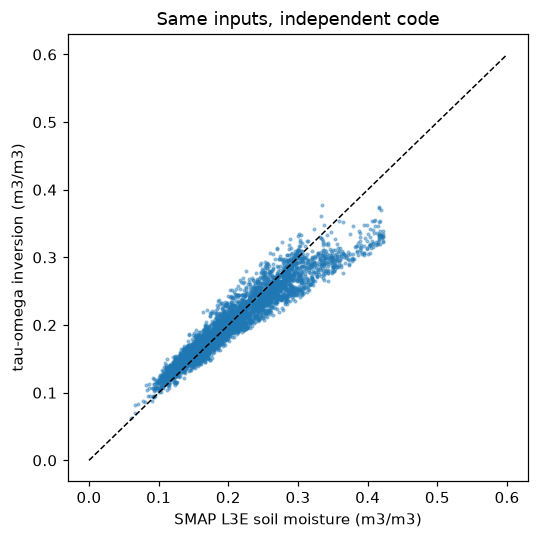

In [9]:
smap = sd.smap_l3e()  # SMAP L3 Enhanced cube, 2015 to 2025, Midwest box
day = smap.sel(time=slice("2024-01-01", "2024-12-31"), overpass="AM")  # AM overpasses of 2024
ames = sd.ease2_clip(day, sd.IOWA["bbox"])  # 9 km cells of the central Iowa field site
ok = ames.sm.notnull() & ames.tb_v_corrected.notnull() & ames.vegetation_opacity.notnull()  # complete retrievals
ours = sm.invert_tau_omega(ames.tb_v_corrected, ames.surface_temperature, 40.0, clay=CLAY, tau=ames.vegetation_opacity,
                           omega=0.05, h=0.108, pol="v", theta_range=(0.02, 0.6)).where(ok)  # our single channel retrieval
d = pd.DataFrame({"SMAP": ames.sm.where(ok).values.ravel(), "GeoLattice SCA-V": ours.values.ravel()}).dropna()  # paired values
diff = d["GeoLattice SCA-V"] - d["SMAP"]  # difference
print(f"{len(d):,} retrievals: R {d.corr().iloc[0, 1]:.3f}, mean difference {diff.mean():+.3f}, "
      f"std {diff.std():.3f} m3/m3, 90 % within {diff.abs().quantile(0.9):.3f}")  # agreement
fig, ax = plt.subplots(figsize=(5, 5)); ax.scatter(d["SMAP"], d["GeoLattice SCA-V"], s=3, alpha=0.4)  # scatter
ax.plot([0, 0.6], [0, 0.6], "k--", lw=1); ax.set_xlabel("SMAP L3E soil moisture (m3/m3)"); ax.set_ylabel("tau-omega inversion (m3/m3)")  # axes
ax.set_title("Same inputs, independent code"); plt.tight_layout(); plt.show()  # draw

Over 4,518 retrievals in 2024 the inversion matches the official SMAP retrieval with a correlation
of 0.958, a mean difference of -0.002 m3 m-3 and a standard deviation of 0.023 (90 % of the
retrievals within 0.036). The scatter that remains comes from inputs not stored in the L3 file or
assumed here: the soil clay of the SMAP ancillary data (we used one
SoilGrids value), the land cover specific `omega` and `h`, and the SMAP effective temperature model.
The exercise shows that, given Tb, temperature and VOD, soil moisture retrieval is a well-posed
one-parameter inversion; the hard part is the ancillary data.

## Summary and exercises

- Water's permittivity of about 80 against 3 to 5 for minerals makes the microwave signal of soil
  moisture large; the Debye relaxation near 17 GHz makes absorption rise with frequency.
- The Dobson and Mironov models differ by 1 to 1.5 units of permittivity over a loam, worth about
  0.02 m3 m-3 of soil moisture.
- L-band senses 6 to 9 cm of moist soil, C-band about 1 cm and X-band half a centimetre.
- Over bare soil Tb V changes by 2.7 K per 0.01 m3 m-3; at an optical depth of 1 only 0.18 K, so VOD
  errors dominate retrieval errors over crops (+0.085 m3 m-3 for a 20 % VOD error at tau 0.6).
- With SMAP's own Tb, temperature and opacity, the GeoLattice tau-omega inversion reproduces the
  SMAP L3 Enhanced soil moisture with R 0.96 and a mean difference of -0.002 m3 m-3.

**Exercises**

1. Recompute the permittivity table with `temperature_c=5` in `sm.dobson_dielectric`. How much does
   a cold soil change the retrieval?
2. Use H polarization in the tau-omega figures. Is H more or less sensitive than V at 40 degrees?
3. Repeat the SMAP reproduction with `sm.dobson_dielectric` (pass `dielectric="dobson"` and `sand=`).
   How large is the systematic difference?
4. Vary `omega` from 0 to 0.1 in `sm.invert_tau_omega` for the SMAP inputs. Which parameter matters
   more for this site, `omega` or `h`?